# Task 3 — Instance segmentation of five plants

For this task I used traditional computer vision to separate the five plants in each image. I wasn't trying to label every leaf or root separately. I just wanted each **whole plant** to have its own label.

I first find the five shoots near the top of the image. Then I look for thin root structures lower down and match each root network to the plant it comes from. I do the root detection across the whole image because some roots grow diagonally and would get cut off if I used five fixed vertical sections.

I tested the code on both images from the assignment, `task_3_image_1.png` and `task_3_image_2.png`. I haven't used any machine learning or deep learning. Everything here is done with OpenCV and NumPy.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

BUILD_ID = "TASK3_GLOBAL_COMPONENTS_01"
print(f"Build: {BUILD_ID}")

# Put the two PNG files in Task 3/images, or set IMAGE_DIR to the folder
# where they are saved on your computer. Both regular filenames and
# downloaded copies ending in " (1).png" are supported.
IMAGE_DIR = None  # Example: Path(r"C:\path\to\your\task3\images")


def find_image(filename):
    """Find a Task 3 input image without relying on my original PC's path."""
    cwd = Path.cwd()
    folders = [
        cwd,
        cwd / "images",
        cwd / "Task 3",
        cwd / "Task 3" / "images",
        cwd / "task3_images",
        cwd.parent / "images",
    ]

    if IMAGE_DIR is not None:
        folders.insert(0, Path(IMAGE_DIR).expanduser())

    names = [filename, filename.replace(".png", " (1).png")]
    for folder in folders:
        for name in names:
            path = folder / name
            if path.is_file():
                return path

    raise FileNotFoundError(
        f"Could not find {filename}. Put it in Task 3/images or set "
        "IMAGE_DIR to the folder containing the Task 3 PNG files."
    )


IMAGE_PATHS = [
    find_image("task_3_image_1.png"),
    find_image("task_3_image_2.png"),
]

Build: TASK3_GLOBAL_COMPONENTS_01


## How I separated the plants

I used a threshold and connected components to pick out the dark shoots at the top. For the roots, I subtracted a blurred background and used short line-shaped kernels at different angles. This helps keep thin structures without including every dark spot in the dish.

After that, I used connected components and a few shape checks to keep the more root-like structures. I matched each root network to the nearest plant at its upper end. The final mask combines the shoot and its root network under **one plant label**.

The functions below contain the details and the parameters I used.

In [2]:
def load_grayscale(path):
    """Load an image and convert it to grayscale without resizing it."""
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")

    if image.ndim == 2:
        return image

    if image.shape[2] == 4:
        return cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2GRAY)

    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def find_plant_centers(gray):
    """
    Detect the five plant x-positions from the dark structures in the upper dish.

    The usable width is divided into five broad regions. A smoothed horizontal
    darkness projection gives one plant center inside each region.
    """
    h, w = gray.shape

    x0, x1 = int(0.22 * w), int(0.82 * w)
    y0, y1 = int(0.08 * h), int(0.24 * h)

    roi = gray[y0:y1, x0:x1].astype(np.float32)

    darkness = np.clip(185.0 - roi, 0.0, None)
    projection = darkness.sum(axis=0)

    projection = cv2.GaussianBlur(
        projection.reshape(1, -1),
        (0, 0),
        sigmaX=8
    ).ravel()

    edges = np.linspace(0, projection.size, 6).astype(int)

    centers = []

    for i in range(5):
        a, b = edges[i], edges[i + 1]
        local_peak = int(np.argmax(projection[a:b]))
        centers.append(int(x0 + a + local_peak))

    return centers


def segment_crown(gray, center_x, threshold=145):
    """
    Segment one shoot/crown.

    Leaves and upper stems are much darker than the gel. A threshold is used,
    but only the connected component passing through the expected plant center
    and reaching the lower crown region is retained. This rejects most droplets.
    """
    h, w = gray.shape

    y0, y1 = int(0.06 * h), int(0.205 * h)
    half_width = int(0.06 * w)

    x0 = max(0, center_x - half_width)
    x1 = min(w, center_x + half_width)

    roi = gray[y0:y1, x0:x1]
    binary = (roi < threshold).astype(np.uint8)

    # Only a tiny closing is used here to reconnect small gaps in leaves/stems.
    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        np.ones((3, 3), dtype=np.uint8)
    )

    n, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )

    local_center = center_x - x0
    best_label = None
    best_score = -np.inf

    for label in range(1, n):
        x, y, bw, bh, area = stats[label]
        cx, cy = centroids[label]

        if area < 50:
            continue

        strip_left = max(0, local_center - 25)
        strip_right = min(labels.shape[1], local_center + 26)

        intersects_center = np.any(
            labels[:, strip_left:strip_right] == label
        )

        bottom = y + bh
        reaches_lower_crown = bottom >= int(0.45 * (y1 - y0))

        if not (intersects_center and reaches_lower_crown):
            continue

        score = area - 4.0 * abs(cx - local_center) + 2.0 * bottom

        if score > best_score:
            best_score = score
            best_label = label

    full_mask = np.zeros_like(gray, dtype=np.uint8)

    if best_label is None:
        return full_mask

    full_mask[y0:y1, x0:x1] = (labels == best_label).astype(np.uint8)

    return full_mask


def make_line_kernel(length, angle_degrees):
    """
    Create a short one-pixel-wide line structuring element.

    Several orientations are used so curved and diagonal roots can be retained
    without using a large closing operation.
    """
    kernel = np.zeros((length, length), dtype=np.uint8)

    center = (length - 1) / 2.0
    angle = np.deg2rad(angle_degrees)

    dx = np.cos(angle) * (length - 1) / 2.0
    dy = np.sin(angle) * (length - 1) / 2.0

    p1 = (
        int(round(center - dx)),
        int(round(center - dy))
    )

    p2 = (
        int(round(center + dx)),
        int(round(center + dy))
    )

    cv2.line(kernel, p1, p2, 1, 1)

    return kernel


LINE_KERNELS = [
    make_line_kernel(9, angle)
    for angle in range(0, 180, 15)
]


def pca_elongation(xs, ys):
    """
    Measure how line-like a connected component is using PCA.

    Large values indicate a long thin structure rather than a compact droplet.
    """
    if len(xs) < 3:
        return 1.0

    points = np.column_stack((xs, ys)).astype(np.float32)
    covariance = np.cov(points, rowvar=False)

    eigenvalues = np.linalg.eigvalsh(covariance)

    return float(
        (eigenvalues[-1] + 1e-6) /
        (eigenvalues[0] + 1e-6)
    )


def root_line_response(gray, mature):
    """
    Enhance thin dark roots while suppressing broad illumination/shadow changes.

    Step 1:
        A 31x31 Gaussian blur estimates the local background.

    Step 2:
        background - image creates a local-darkness response.
        A broad shadow changes slowly, so its response stays small.
        Thin roots are locally much darker, so they remain strong.

    Step 3:
        Multi-angle grayscale morphological opening keeps structures that
        behave like short lines. Droplets are much more compact/circular.
    """
    h, w = gray.shape

    x0, x1 = int(0.20 * w), int(0.84 * w)

    if mature:
        y0, y1 = int(0.155 * h), int(0.50 * h)
    else:
        y0, y1 = int(0.10 * h), int(0.36 * h)

    roi = gray[y0:y1, x0:x1]

    background = cv2.GaussianBlur(
        roi,
        (31, 31),
        0
    )

    local_darkness = cv2.subtract(background, roi)

    response = np.zeros_like(local_darkness)

    for kernel in LINE_KERNELS:
        opened = cv2.morphologyEx(
            local_darkness,
            cv2.MORPH_OPEN,
            kernel
        )

        response = np.maximum(response, opened)

    return response, (x0, x1, y0, y1)


def segment_root_networks(gray, centers, mature):
    """
    Segment all five root systems globally.

    This is intentionally NOT done in five fixed vertical lanes.

    Why:
    Some roots grow diagonally and cross the midpoint between neighboring
    plants. A lane-based method either cuts those roots or gives part of one
    plant to another instance.

    Instead, the line-enhanced root image is converted to connected components.
    Each large, sparse, line-like network is matched to the plant whose center
    is closest to the network's *upper origin*. The complete component then
    receives that plant label, even if it later crosses a midpoint.
    """
    response, (x0, x1, y0, y1) = root_line_response(
        gray,
        mature
    )

    # A deliberately low threshold retains weak roots.
    # Compact false detections are handled by component geometry afterwards.
    candidate = (response >= 2).astype(np.uint8)

    n, component_labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            candidate,
            connectivity=8
        )
    )

    components = []

    minimum_area = 500 if mature else 100

    for label in range(1, n):
        x, y, bw, bh, area = stats[label]

        if area < minimum_area:
            continue

        if max(bw, bh) < 30:
            continue

        ys, xs = np.where(component_labels == label)

        fill_ratio = area / float(bw * bh)
        elongation = pca_elongation(xs, ys)

        # A dish edge or compact droplet cluster is much denser than a root network.
        if fill_ratio > 0.35:
            continue

        if elongation < 3.0:
            continue

        top_y = ys.min()
        top_band = xs[ys <= top_y + 8]

        if top_band.size == 0:
            top_x_global = float(centroids[label][0] + x0)
        else:
            top_x_global = float(np.median(top_band) + x0)

        components.append(
            {
                "label": label,
                "area": int(area),
                "top_x": top_x_global,
                "fill_ratio": float(fill_ratio),
                "elongation": float(elongation),
            }
        )

    root_labels = np.zeros_like(gray, dtype=np.uint8)
    used_components = set()

    max_origin_distance = 100 if mature else 75

    for instance_id, center_x in enumerate(centers, start=1):
        available = [
            component
            for component in components
            if component["label"] not in used_components
        ]

        available.sort(
            key=lambda component: (
                abs(component["top_x"] - center_x),
                -component["area"]
            )
        )

        chosen = None

        for component in available:
            if abs(component["top_x"] - center_x) <= max_origin_distance:
                chosen = component
                break

        if chosen is None:
            continue

        used_components.add(chosen["label"])

        local_mask = (
            component_labels == chosen["label"]
        )

        full_mask = np.zeros_like(gray, dtype=np.uint8)
        full_mask[y0:y1, x0:x1] = local_mask.astype(np.uint8)

        root_labels[full_mask.astype(bool)] = instance_id

    return root_labels, response


def segment_plants(gray):
    """
    Segment five plant instances from one image.

    Returns
    -------
    instance_labels : uint8 array
        0 = background, 1..5 = plants from left to right.

    centers : list[int]
        Detected horizontal centers.

    mature : bool
        Automatically inferred from crown size.

    root_response : uint8 array
        Intermediate line-enhancement image for inspection.
    """
    centers = find_plant_centers(gray)

    crowns = [
        segment_crown(gray, center)
        for center in centers
    ]

    crown_areas = [
        int(crown.sum())
        for crown in crowns
    ]

    # The second image has much larger shoots.
    # This is determined from the image itself, not the filename.
    mature = np.median(crown_areas) > 2500

    root_labels, root_response = segment_root_networks(
        gray,
        centers,
        mature
    )

    instance_labels = np.zeros_like(gray, dtype=np.uint8)

    for instance_id, crown in enumerate(crowns, start=1):
        instance_labels[crown.astype(bool)] = instance_id
        instance_labels[root_labels == instance_id] = instance_id

    return instance_labels, centers, mature, root_response


def labels_to_rgb(labels):
    """Convert labels 0..5 to assignment-style colors."""
    colors = np.array([
        [68, 1, 84],      # background
        [72, 40, 120],    # plant 1
        [49, 104, 142],   # plant 2
        [31, 158, 137],   # plant 3
        [107, 205, 89],   # plant 4
        [253, 231, 37],   # plant 5
    ], dtype=np.uint8)

    return colors[labels]


## Running both assignment images

I run the same `segment_plants()` function on both images. The code works out which one has larger shoots using the image itself, not the filename.

I also check that labels 1–5 are present and print the pixel counts, so I can catch an empty plant mask.

In [3]:
results = []

for path in IMAGE_PATHS:
    gray = load_grayscale(path)

    labels, centers, mature, root_response = segment_plants(gray)

    present = set(np.unique(labels))

    assert {1, 2, 3, 4, 5}.issubset(present), (
        f"Five instances were not found in {path.name}: "
        f"{sorted(present)}"
    )

    areas = [
        int((labels == instance_id).sum())
        for instance_id in range(1, 6)
    ]

    print(
        f"{path.name}: "
        f"centers={centers}, "
        f"mature={mature}, "
        f"areas={areas}"
    )

    results.append(
        (path, gray, labels, centers, mature, root_response)
    )

task_3_image_1 (1).png: centers=[1134, 1635, 2146, 2676, 3185], mature=True, areas=[7376, 5756, 4726, 4936, 4820]
task_3_image_2 (1).png: centers=[1127, 1604, 2205, 2649, 3168], mature=True, areas=[41805, 44888, 48404, 40187, 39961]


## Looking at the results

I plot the original image next to the segmented version so I can check the five plants visually. The background has label 0, and the plants are labelled from 1 to 5, left to right.

The code also prints the detected plant positions and the number of pixels assigned to each plant. I use this as a basic check that none of the five labels ended up empty.

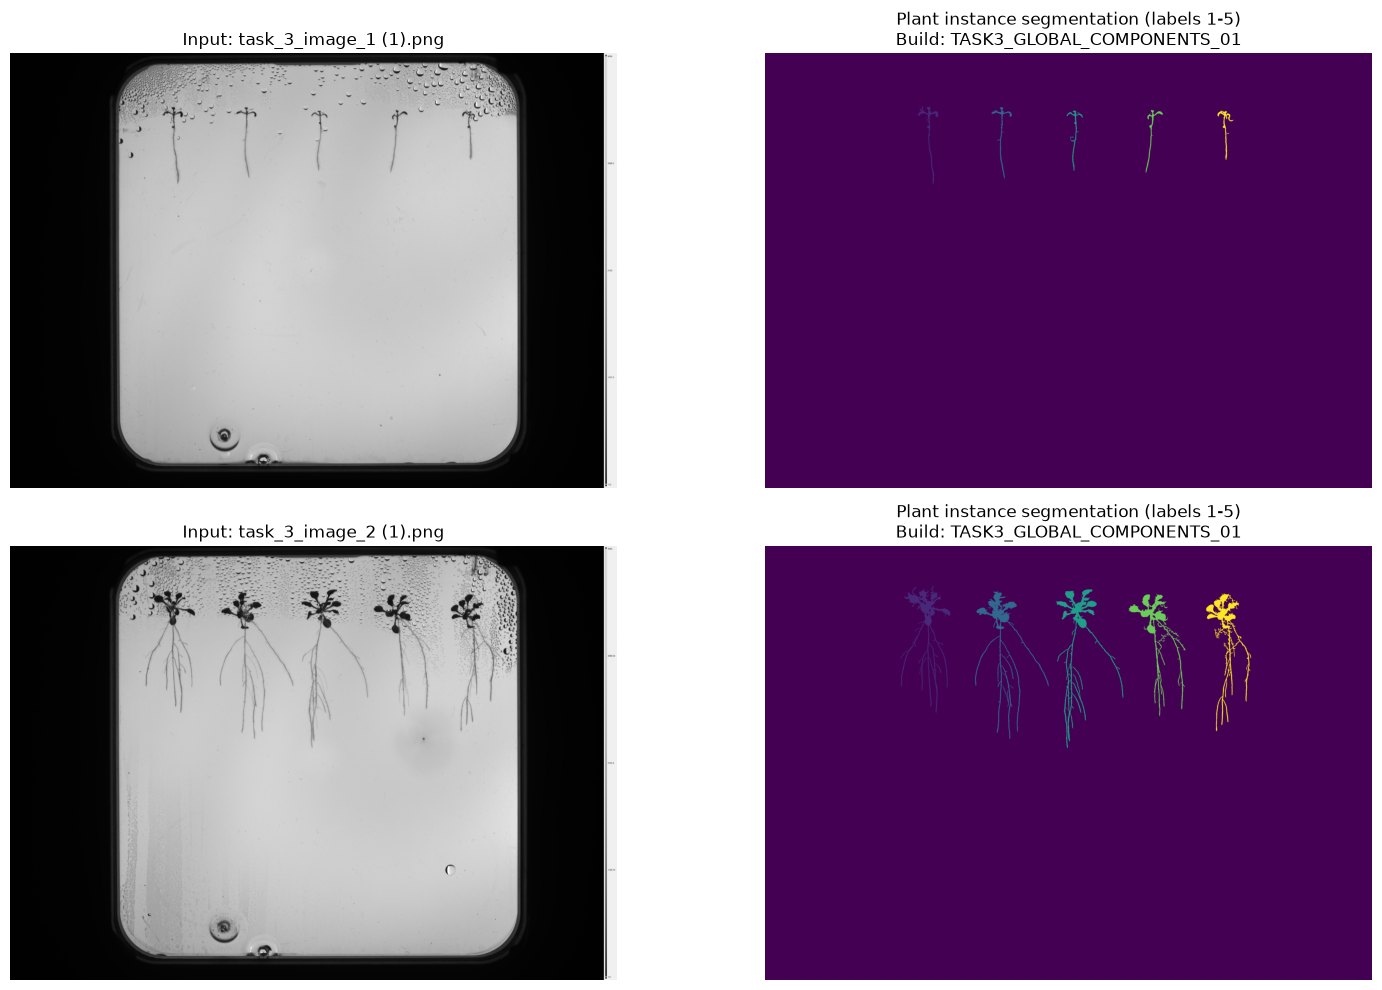

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row, (path, gray, labels, centers, mature, root_response) in enumerate(results):
    axes[row, 0].imshow(gray, cmap="gray")
    axes[row, 0].set_title(f"Input: {path.name}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(labels_to_rgb(labels))
    axes[row, 1].set_title(
        "Plant instance segmentation (labels 1-5)\n"
        f"Build: {BUILD_ID}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

## My check

Both saved runs produced five non-empty plant labels, and the output figures show the plants separately in both required images. The second image has much larger roots, so I wanted to make sure the method still worked without manually splitting the image into five strips.

Some thin, faint roots are harder to keep with traditional CV, but the aim of this task is to separate the **five plants**, not to trace every individual root. The saved plots above are the results I used to check the segmentation visually.